In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

In [37]:
df_master = pd.read_csv('data_marketing_growth_analytics.csv')
df_before = df_master.copy()
df = df_master.copy()
df.head()

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0


## Data Preparation

In [38]:
df = df_master.copy()
cleaning_log = []
def log(langkah, temuan, baris_terdampak, tindakan):
    cleaning_log.append({'langkah': langkah, 'temuan': temuan, 'baris_terdampak': baris_terdampak, 'tindakan': tindakan})
print('Salinan dibuat. Cleaning log kosong, siap diisi.')

Salinan dibuat. Cleaning log kosong, siap diisi.


### 1. Pemahaman Struktur Dataset

In [39]:
print(f'Jumlah baris : {df.shape[0]:,}')
print(f'Jumlah kolom : {df.shape[1]}')
df.info()

Jumlah baris : 800
Jumlah kolom : 16
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


In [40]:
# Pemisahan tipe kolom
num_cols = ['sessions','page_views','revenue','ad_cost','clicks','impressions','retention_month']
bin_cols = ['bounce','add_to_cart','purchase','repeat_purchase']
cat_cols = ['channel','source','device']
print('Unique user_id :', df.user_id.nunique(), '(baris =', len(df), ')')
df[cat_cols].nunique()

Unique user_id : 800 (baris = 800 )


channel    5
source     6
device     3
dtype: int64

### 2. Pemeriksaan Missing Value

In [41]:
miss = df.isna().sum().to_frame('missing')
miss['persen'] = miss['missing'] / len(df) * 100
miss['n_unique'] = df.nunique()
display(miss)

placeholder = {'', ' ', '-', 'na', 'n/a', 'null', 'none', 'unknown', '?'}
hidden = {}
for c in df.select_dtypes(exclude='number').columns:
    hidden[c] = df[c].astype(str).str.strip().str.lower().isin(placeholder).sum()
print('\nMissing tersembunyi (kolom teks):', hidden)
print('Total missing eksplisit:', int(df.isna().sum().sum()))

,missing,persen,n_unique
user_id,0,0.00,800
first_visit_date,0,0.00,60
channel,0,0.00,5
source,0,0.00,6
device,0,0.00,3
sessions,0,0.00,7
page_views,0,0.00,19
bounce,0,0.00,2
add_to_cart,0,0.00,2
purchase,0,0.00,2



Missing tersembunyi (kolom teks): {'first_visit_date': np.int64(0), 'channel': np.int64(0), 'source': np.int64(0), 'device': np.int64(0)}
Total missing eksplisit: 0


### 3. Pemeriksaan Duplikasi

In [42]:
print('Jumlah duplikat data :', df.duplicated().sum())

Jumlah duplikat data : 0


### 4. Pemeriksaan Konsistensi Kategori

In [43]:
for c in ['channel', 'source', 'device']:
    spasi = (df[c] != df[c].str.strip()).sum()
    variasi_case = df[c].str.strip().str.lower().nunique() != df[c].nunique()
    print(f'{c:8s} | spasi berlebih: {spasi} | variasi huruf: {variasi_case} | kategori: {sorted(df[c].unique())}')

for c in ['channel', 'source', 'device']:
    df[c] = df[c].str.strip()

print()
display(pd.crosstab(df['channel'], df['source']))

channel  | spasi berlebih: 0 | variasi huruf: False | kategori: ['Email', 'Organic Search', 'Paid Ads', 'Referral', 'Social Media']
source   | spasi berlebih: 0 | variasi huruf: False | kategori: ['direct', 'email', 'facebook', 'google', 'instagram', 'tiktok']
device   | spasi berlebih: 0 | variasi huruf: False | kategori: ['Desktop', 'Mobile', 'Tablet']



source,direct,email,facebook,google,instagram,tiktok
channel,,,,,,
Email,13,24,24,20,24,20
Organic Search,30,29,27,36,45,31
Paid Ads,45,43,40,42,41,40
Referral,15,13,11,14,12,10
Social Media,24,21,30,26,21,29


### 5. Perbaikan Tipe Data

In [44]:
df['first_visit_date'] = pd.to_datetime(df['first_visit_date'], errors='coerce')
print('Tanggal gagal diparse :', df['first_visit_date'].isna().sum())
print('Rentang tanggal       :', df['first_visit_date'].min().date(), 's.d.', df['first_visit_date'].max().date())

for c in ['channel', 'source', 'device']:
    df[c] = df[c].astype('category')

print()
print(df.dtypes)

Tanggal gagal diparse : 0
Rentang tanggal       : 2025-01-01 s.d. 2025-03-01

user_id                      int64
first_visit_date    datetime64[us]
channel                   category
source                    category
device                    category
sessions                     int64
page_views                   int64
bounce                       int64
add_to_cart                  int64
purchase                     int64
revenue                      int64
ad_cost                      int64
clicks                       int64
impressions                  int64
repeat_purchase              int64
retention_month              int64
dtype: object


### 6. Validasi Rentang Nilai
Memastikan nilai berada pada rentang yang masuk akal: tidak negatif, biner hanya 0/1, minimum sesi dan page view >= 1.

In [45]:
num_cols = ['sessions', 'page_views', 'revenue', 'ad_cost', 'clicks', 'impressions', 'retention_month']
bin_cols = ['bounce', 'add_to_cart', 'purchase', 'repeat_purchase']

rng = pd.DataFrame({
    'min': df[num_cols].min(),
    'max': df[num_cols].max(),
    'negatif': (df[num_cols] < 0).sum(),
})
display(rng)

print('Nilai non-biner pada kolom biner:')
for c in bin_cols:
    print(f'  {c:16s}: {(~df[c].isin([0, 1])).sum()}')
print('\nsessions < 1    :', (df['sessions'] < 1).sum())
print('page_views < 1  :', (df['page_views'] < 1).sum())

,min,max,negatif
sessions,1,7,0
page_views,1,19,0
revenue,0,495675,0
ad_cost,0,79437,0
clicks,1,49,0
impressions,8,1911,0
retention_month,0,5,0


Nilai non-biner pada kolom biner:
  bounce          : 0
  add_to_cart     : 0
  purchase        : 0
  repeat_purchase : 0

sessions < 1    : 0
page_views < 1  : 0


### 8. Deteksi Outlier (IQR)

,Q1,Q3,batas_bawah,batas_atas,outlier_IQR
kolom,,,,,
sessions,3.00,6.00,-1.50,10.50,0
page_views,5.00,15.00,-10.00,30.00,0
revenue,0.00,0.00,0.00,0.00,150
ad_cost,0.00,"21,996.75","-32,995.12","54,991.88",89
clicks,11.00,37.00,-28.00,76.00,0
impressions,208.75,812.00,-696.12,"1,716.88",7
retention_month,0.00,0.00,0.00,0.00,150


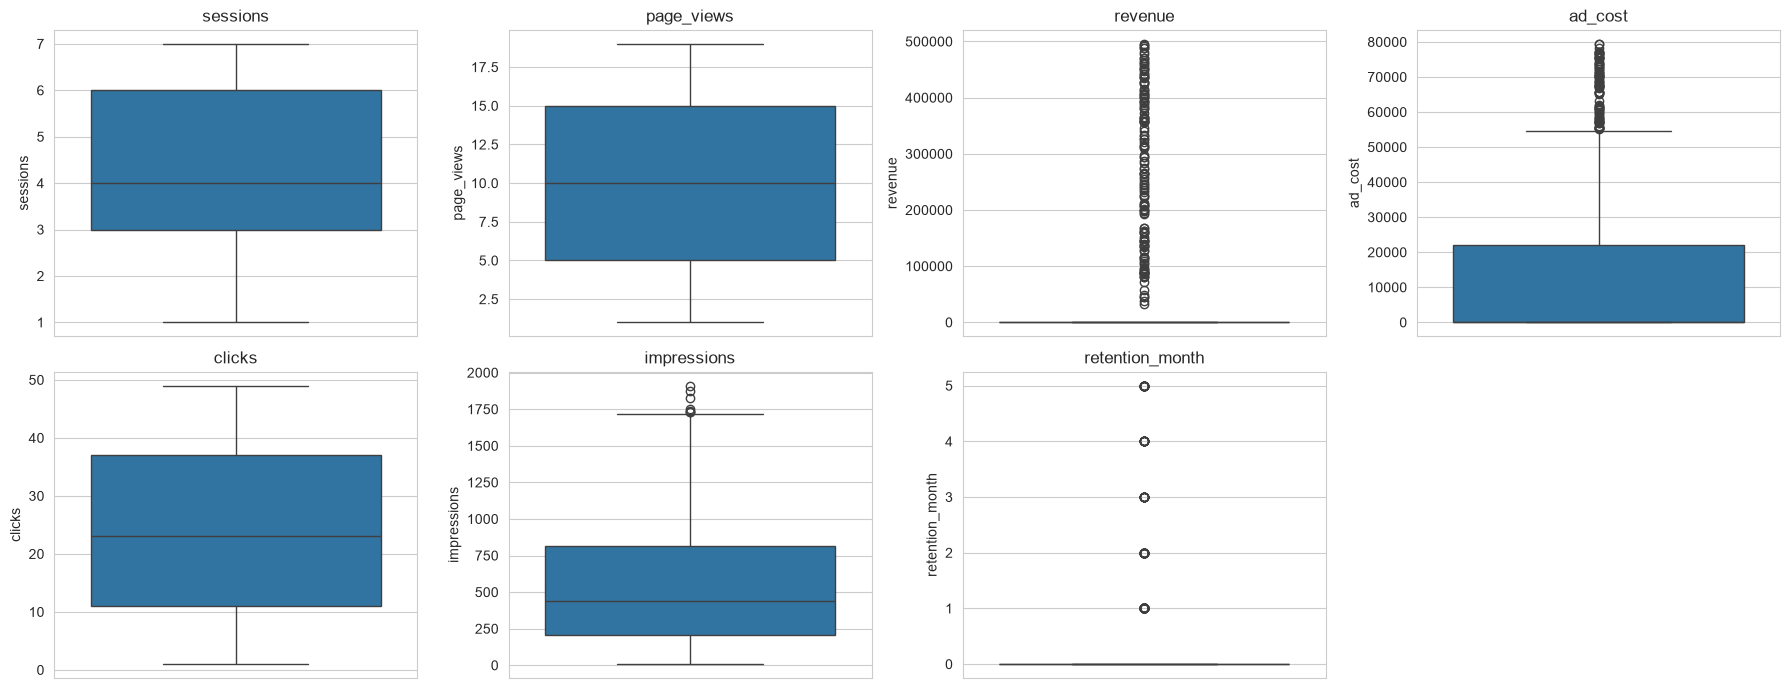

In [46]:
def outlier_table(data, cols):
    out = []
    for c in cols:
        s = data[c]
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        z = (s - s.mean()) / s.std()
        out.append({'kolom': c, 'Q1': q1, 'Q3': q3, 'batas_bawah': lo, 'batas_atas': hi,
                    'outlier_IQR': int(((s < lo) | (s > hi)).sum())})
    return pd.DataFrame(out).set_index('kolom')

display(outlier_table(df, num_cols))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

#### Penjelasan: outlier
- **Keputusan:** **tidak ada yang dibuang atau di-cap.** Menghapus pembeli bernilai tinggi justru menghilangkan informasi terpenting. Untuk analisis bivariat dipakai uji non-parametrik (Mann-Whitney, Kruskal-Wallis) yang tahan terhadap sebaran miring.

In [47]:
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
sessions,800.00,4.13,1.97,1.00,3.00,4.00,6.00,7.00
page_views,800.00,10.05,5.48,1.00,5.00,10.00,15.00,19.00
revenue,800.00,"51,254.88","121,909.73",0.00,0.00,0.00,0.00,"495,675.00"
ad_cost,800.00,"13,686.13","23,499.47",0.00,0.00,0.00,"21,996.75","79,437.00"
clicks,800.00,24.37,14.37,1.00,11.00,23.00,37.00,49.00
impressions,800.00,553.38,427.27,8.00,208.75,442.00,812.00,"1,911.00"
retention_month,800.00,0.43,1.10,0.00,0.00,0.00,0.00,5.00


### 9.Feature Engineering

In [48]:
# ===== Fitur turunan (dipakai di seluruh analisis & Tableau) =====
df['tipe_channel']      = np.where(df.ad_cost > 0, 'Paid', 'Gratis')       # Paid = ada biaya iklan
df['revenue_bersih']    = df.revenue - df.ad_cost                          # revenue setelah biaya iklan
df['ctr']               = df.clicks / df.impressions
df['pages_per_session'] = df.page_views / df.sessions
df['roas_user']         = df.revenue / df.ad_cost.where(df.ad_cost > 0)    # kosong untuk user gratis
df['status_pembeli']    = np.where(df.purchase == 1, 'Pembeli', 'Bukan Pembeli')
df['status_repeat']     = np.where(df.repeat_purchase == 1, 'Repeat', np.where(df.purchase == 1, 'Sekali Beli', 'Bukan Pembeli'))

print(pd.crosstab(df.channel, df.tipe_channel))

tipe_channel    Gratis  Paid
channel                     
Email              125     0
Organic Search     198     0
Paid Ads             0   251
Referral            75     0
Social Media       151     0


In [49]:
checks = {
    'jumlah baris sama dengan data mentah'          : len(df) == len(df_master),
    'user_id unik'                                  : df.user_id.is_unique,
    'tidak ada missing value'                       : df.isna().sum().sum() == 0,
    'nilai kolom mentah tidak berubah (hanya tipe)': bool((df[df_master.columns].astype(str) == df_master.astype(str)).all().all())
}
display(pd.Series(checks, name='lolos?').to_frame())
df.to_csv('data_clean.csv', index=False)
print(f'Tersimpan: data_clean.csv -> {df.shape[0]} baris x {df.shape[1]} kolom')

,lolos?
jumlah baris sama dengan data mentah,True
user_id unik,True
tidak ada missing value,False
nilai kolom mentah tidak berubah (hanya tipe),True


Tersimpan: data_clean.csv -> 800 baris x 23 kolom


## Exploration Data Analysis (EDA)

### Analisis Univariat

#### Variabel Katagorikal

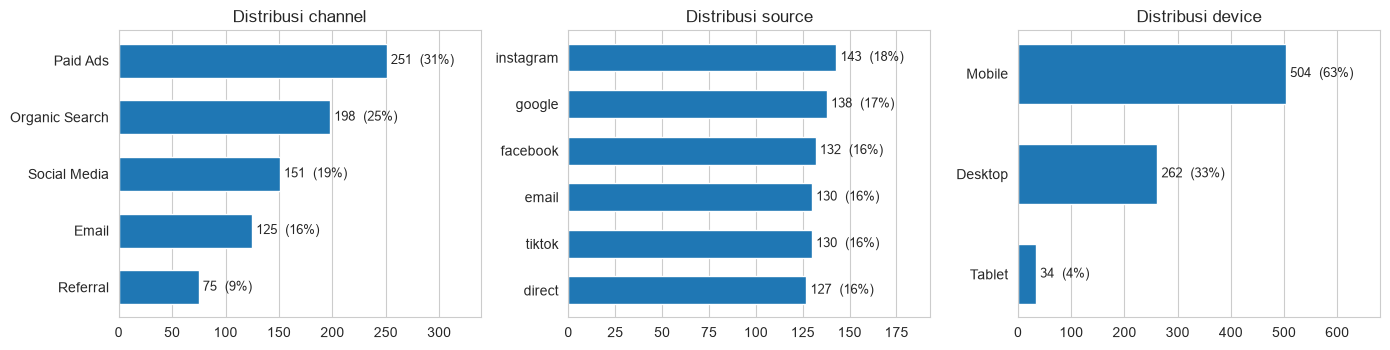

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, c in zip(axes, cat_cols):
    vc = df[c].value_counts()
    b = ax.barh(vc.index[::-1], vc.values[::-1], height=0.6)
    for bar, v in zip(b, vc.values[::-1]): ax.text(v, bar.get_y() + bar.get_height()/2, f' {v}  ({v/len(df)*100:.0f}%)', va='center', fontsize=9)
    ax.set_xlim(0, vc.max() * 1.35); ax.set_title(f'Distribusi {c}'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

#### Variabel Numerik

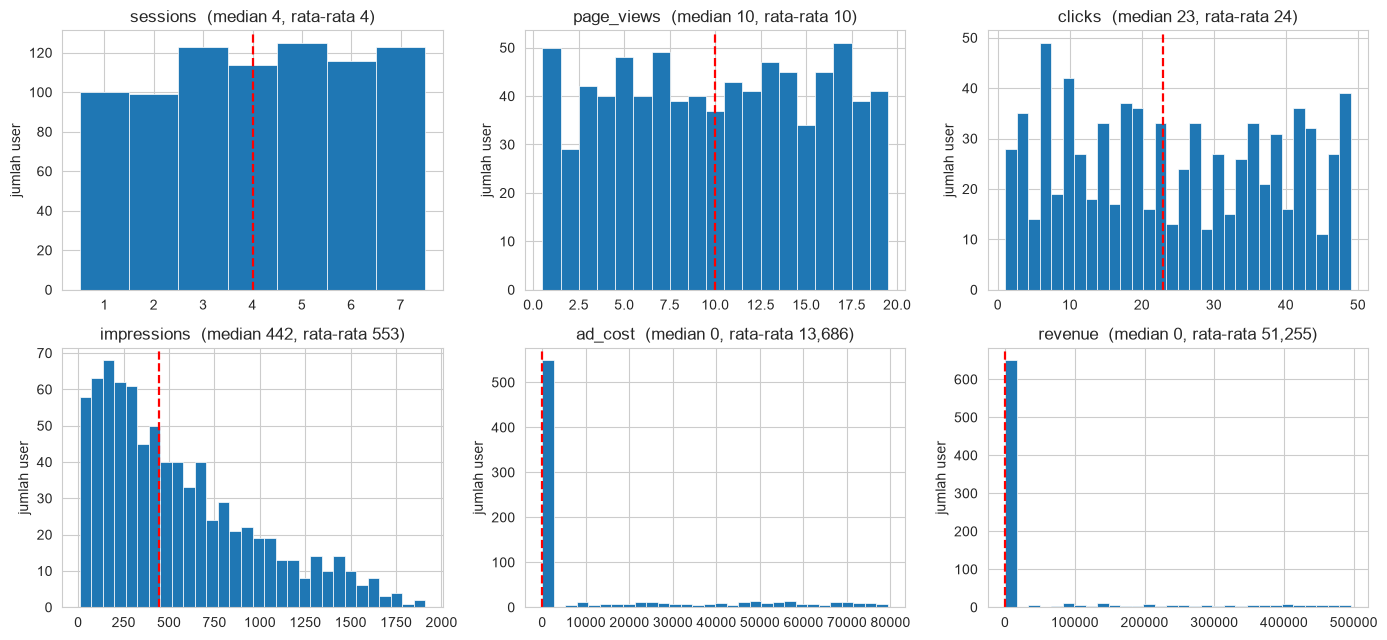

,skew,kurtosis,% nilai nol
sessions,-0.08,-1.20,0.00
page_views,-0.02,-1.21,0.00
clicks,0.10,-1.26,0.00
impressions,0.90,0.04,0.00
ad_cost,1.48,0.69,68.62
revenue,2.34,4.17,81.25


In [51]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, c in zip(axes.ravel(), ['sessions', 'page_views', 'clicks', 'impressions', 'ad_cost', 'revenue']):
    bins_ = np.arange(df[c].min() - 0.5, df[c].max() + 1.5) if df[c].nunique() <= 20 else 30
    ax.hist(df[c], bins=bins_, edgecolor='white', linewidth=0.5)
    ax.axvline(df[c].median(), color='red', lw=1.6, ls='--')
    ax.set_title(f'{c}  (median {df[c].median():,.0f}, rata-rata {df[c].mean():,.0f})')
    ax.set_ylabel('jumlah user')
plt.tight_layout(); plt.show()

summ = pd.DataFrame({'skew': df[['sessions','page_views','clicks','impressions','ad_cost','revenue']].skew(),
                     'kurtosis': df[['sessions','page_views','clicks','impressions','ad_cost','revenue']].kurt(),
                     '% nilai nol': (df[['sessions','page_views','clicks','impressions','ad_cost','revenue']] == 0).mean() * 100})
summ

**Interpretasi sebaran variabel numerik (univariat):**
  - **`sessions`, `page_views`, `clicks` berbentuk uniform (merata):** tiap nilai muncul dengan frekuensi serupa, tidak ada puncak. Kurtosis ≈ −1,2 (khas distribusi seragam).
  - **`impressions` miring kanan:** banyak user dengan tayangan rendah (puncak di ±100–300), ekor panjang hingga 1.900; median 442 < rata-rata 553.
  - **`ad_cost` dan `revenue` didominasi satu batang di nol** (68,6% dan 81,25%); sebaran nilai positifnya terlihat pada cell berikutnya.

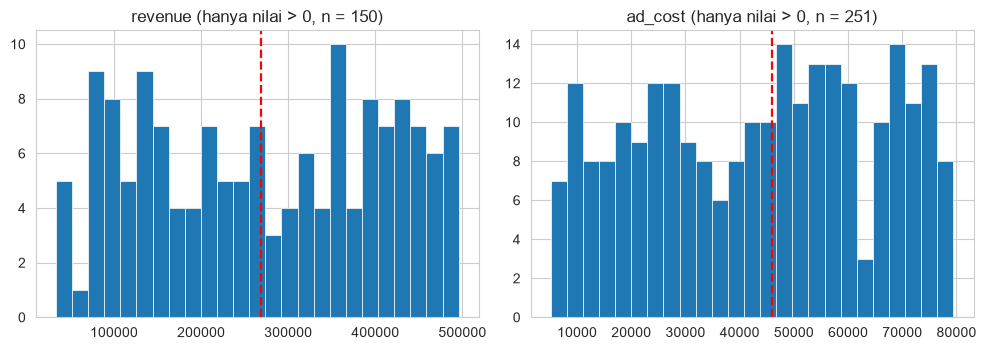

                 count       mean        std       min        25%        50%        75%        max
revenue pembeli 150.00 273,359.00 136,288.00 33,251.00 144,548.00 269,230.00 397,801.00 495,675.00
                    count      mean       std      min       25%       50%       75%       max
ad_cost user iklan 251.00 43,621.00 21,305.00 5,126.00 24,780.00 45,942.00 60,952.00 79,437.00


In [52]:
# Kolom zero-inflated: lihat sebaran nilai > 0 saja
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (c, d_) in zip(axes, [('revenue', df[df.revenue > 0]), ('ad_cost', df[df.ad_cost > 0])]):
    ax.hist(d_[c], bins=25, edgecolor='white', linewidth=0.5)
    ax.axvline(d_[c].median(), color='red', ls='--', lw=1.6)
    ax.set_title(f'{c} (hanya nilai > 0, n = {len(d_)})')
plt.tight_layout(); plt.show()
print(df.loc[df.revenue > 0, 'revenue'].describe().round(0).to_frame('revenue pembeli').T.to_string())
print(df.loc[df.ad_cost > 0, 'ad_cost'].describe().round(0).to_frame('ad_cost user iklan').T.to_string())

**Insight variabel zero-inflated (nilai > 0)**
  - **Revenue pembeli (n = 150):** Rp33 rb – Rp496 rb, median ≈ **Rp269 rb**, rata-rata ≈ Rp273 rb. Sebarannya **lebar dan relatif merata** tanpa "harga standar" yang dominan.
  - **Ad cost user iklan (n = 251):** Rp5,1 rb – Rp79,4 rb, median ≈ **Rp45,9 rb**, rata-rata Rp43,6 rb; biaya per user bervariasi hampir 15 kali lipat.
  - **Retention pembeli:** 68 pembeli bertahan 1 bulan, 32 selama 2, 14 selama 3, 12 selama 4, dan **24 selama 5**. Lonjakan di bulan ke-5 (vs 12 di bulan ke-4) menunjukkan nilai 5 mungkin berarti "5 bulan atau lebih" (*top-coded*); retention juga melebihi periode data (2 bulan), jadi **definisinya perlu dikonfirmasi**.

#### Variabel Waktu

Rentang tanggal: 2025-01-01 s.d. 2025-03-01


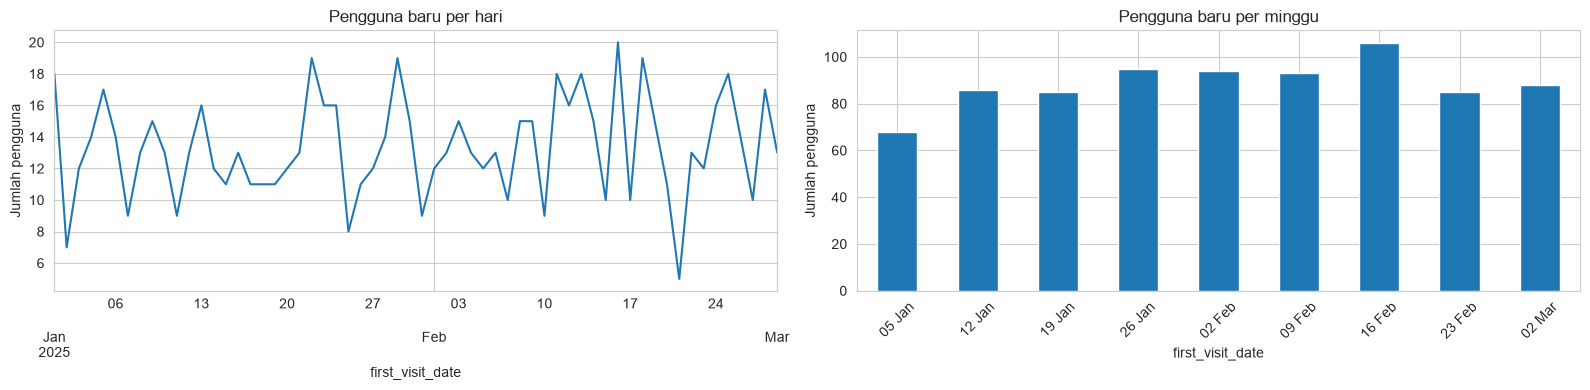

first_visit_date
2025-01    403
2025-02    384
2025-03     13
Freq: M, dtype: int64


In [53]:
df['first_visit_date'] = pd.to_datetime(df['first_visit_date'])
print('Rentang tanggal:', df['first_visit_date'].min().date(), 's.d.', df['first_visit_date'].max().date())

daily = df.groupby('first_visit_date').size()
weekly = df.set_index('first_visit_date').resample('W').size()

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
daily.plot(ax=axes[0])
axes[0].set_title('Pengguna baru per hari'); axes[0].set_ylabel('Jumlah pengguna')
weekly.plot(kind='bar', ax=axes[1])
axes[1].set_title('Pengguna baru per minggu'); axes[1].set_ylabel('Jumlah pengguna')
axes[1].set_xticklabels([d.strftime('%d %b') for d in weekly.index], rotation=45)
plt.tight_layout(); plt.show()

print(df.groupby(df['first_visit_date'].dt.to_period('M')).size())

### Analisis Bivariat

,ukuran_cohort,M0,M1,M2,M3,M4,M5
2025-01,403,100%,19%,12%,7%,5%,2%
2025-02,384,100%,18%,9%,6%,4%,4%
2025-03,13,100%,23%,8%,8%,8%,0%


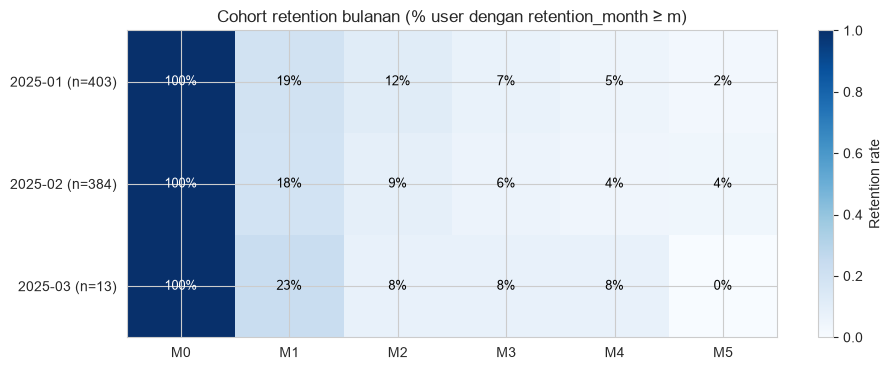

In [54]:
# --- Cohort retention: cohort = bulan kunjungan pertama ---
df['cohort'] = df.first_visit_date.dt.to_period('M').astype(str)

max_m = int(df.retention_month.max())
rows = {}
for coh, g in df.groupby('cohort'):
    rows[coh] = [(g.retention_month >= m).mean() for m in range(0, max_m + 1)]

cohort_ret = pd.DataFrame(rows, index=[f'M{m}' for m in range(0, max_m + 1)]).T
cohort_ret.insert(0, 'ukuran_cohort', df.groupby('cohort').size())

display(cohort_ret.style
        .format({c: '{:.0%}' for c in cohort_ret.columns if c != 'ukuran_cohort'})
        .background_gradient(cmap='Blues', subset=[c for c in cohort_ret.columns if c != 'ukuran_cohort'], vmin=0, vmax=1))

# Heatmap
data = cohort_ret.drop(columns='ukuran_cohort')
fig, ax = plt.subplots(figsize=(1.1 * (max_m + 1) + 3, 0.6 * len(data) + 2)) 
im = ax.imshow(data.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')

ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(data.columns)
ax.set_yticks(range(len(data))); ax.set_yticklabels([f'{i} (n={n})' for i, n in zip(data.index, cohort_ret.ukuran_cohort)])

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.iat[i, j]
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=9, color='white' if v > 0.55 else 'black')
        
ax.set_title('Cohort retention bulanan (% user dengan retention_month ≥ m)')
fig.colorbar(im, ax=ax, label='Retention rate')
plt.tight_layout(); plt.show()

**insight**:

* **Penurunan Tajam (Churn Tinggi) di Bulan Pertama (M1):** Terjadi kehilangan *user* secara masif sesaat setelah mereka diakuisisi. Retensi turun drastis dari 100% (M0) menjadi hanya 19% untuk cohort 2025-01 dan 18% untuk cohort 2025-02 di bulan pertama (M1). Hal ini mengindikasikan bahwa sekitar 81-82% *user* baru tidak kembali lagi setelah bulan interaksi pertama mereka.

* **Tren Jangka Panjang yang Terus Menyusut:** Persentase *user* yang bertahan terus mengalami tren penurunan *steady* dari bulan ke bulan. Pada bulan kelima (M5), tingkat retensi berada pada titik yang sangat rendah, yaitu hanya tersisa 2% untuk cohort Januari dan 4% untuk cohort Februari.

**Area Fokus Utama:**
Peluang perbaikan terbesar (*bottleneck*) berada di rentang transisi dari **M0 ke M1**. Inisiatif bisnis sebaiknya difokuskan pada perbaikan *user onboarding*, aktivasi produk, atau penawaran insentif dalam 30 hari pertama untuk mengerem laju *churn* yang ekstrim di awal periode.

### Analisis Multivariat

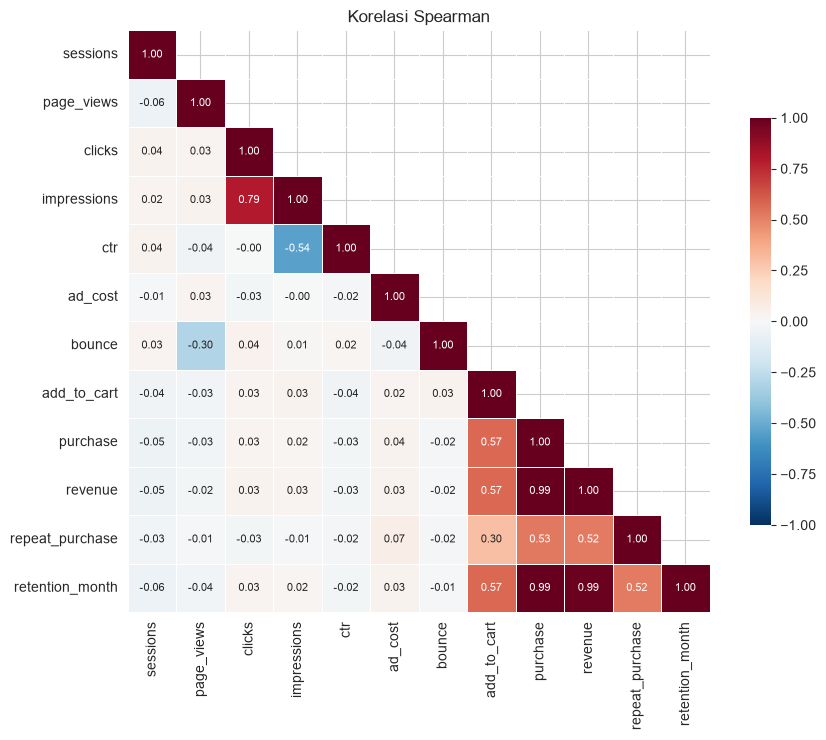

rho
retention_month purchase     0.99
revenue         purchase     0.99
retention_month revenue      0.99
impressions     clicks       0.79
purchase        add_to_cart  0.57
retention_month add_to_cart  0.57
revenue         add_to_cart  0.57
ctr             impressions -0.54
repeat_purchase purchase     0.53
                revenue      0.52

In [55]:
corr_cols = ['sessions', 'page_views', 'clicks', 'impressions', 'ctr', 'ad_cost', 'bounce', 'add_to_cart', 'purchase', 'revenue', 'repeat_purchase', 'retention_month']
corr = df[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor='white', annot_kws={'size': 8}, cbar_kws={'shrink': 0.7})
plt.title('Korelasi Spearman'); plt.tight_layout(); plt.show()

pairs_ = corr.where(~mask).stack(); pairs_ = pairs_[pairs_.index.get_level_values(0) != pairs_.index.get_level_values(1)]
top = pairs_.reindex(pairs_.abs().sort_values(ascending=False).index).head(10).rename('rho').to_frame()
top

## Analisis Efektivitas Paid Ads vs Non-Paid Ads

Perusahaan memperoleh pengguna dari dua jenis saluran: **Paid Ads** yang memerlukan biaya iklan, serta **channel gratis** (Email, Organic Search, Referral, dan Social Media). Sebelum anggaran iklan dilanjutkan atau ditambah, perlu dipastikan bahwa iklan berbayar memberikan hasil yang sepadan dengan biayanya.

> **Problem statement:** Apakah paid ads lebih efektif dibandingkan channel gratis, dan apakah anggaran iklan layak dilanjutkan, ditingkatkan, atau dioptimasi?


In [56]:
sns.set_style('whitegrid')
C_PAID, C_FREE = '#E4572E', '#2E86AB'
pd.options.display.float_format = '{:,.2f}'.format

### Komposisi Pengguna: Paid Ads dan Channel Gratis
Proporsi pengguna dan total pendapatan kotor pada setiap channel.

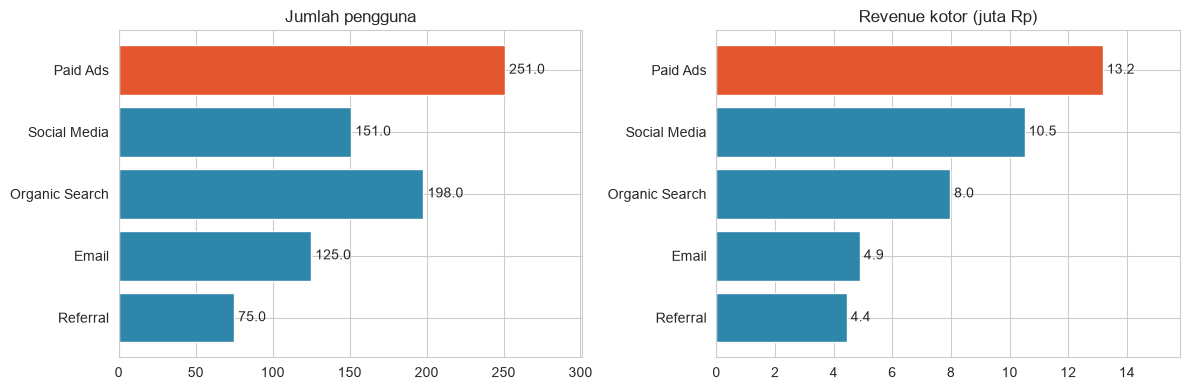

              pengguna  persen
tipe_channel                  
Gratis             549   68.62
Paid               251   31.37


In [57]:
ch = df.groupby('channel').agg(pengguna=('user_id','count'), revenue=('revenue','sum')).sort_values('revenue', ascending=False)
warna = [C_PAID if i == 'Paid Ads' else C_FREE for i in ch.index]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, t in [(ax[0], ch.pengguna, 'Jumlah pengguna'), (ax[1], ch.revenue/1e6, 'Revenue kotor (juta Rp)')]:
    a.barh(ch.index[::-1], col[::-1], color=warna[::-1]); a.set_title(t)
    for i, v in enumerate(col[::-1]): a.text(v, i, f' {v:,.0f}' if col is ch.pengguna else f' {v:,.1f}', va='center')
    a.set_xlim(0, col.max()*1.2)
plt.tight_layout(); plt.show()
print(df.tipe_channel.value_counts().to_frame('pengguna').assign(persen=lambda x: x.pengguna/len(df)*100))

**Temuan:** Sebanyak 251 dari 800 pengguna (sekitar 31%) berasal dari Paid Ads, dan channel ini menghasilkan pendapatan kotor terbesar. Namun, pendapatan kotor belum memperhitungkan biaya iklan sehingga belum cukup untuk menyimpulkan bahwa Paid Ads lebih efektif.

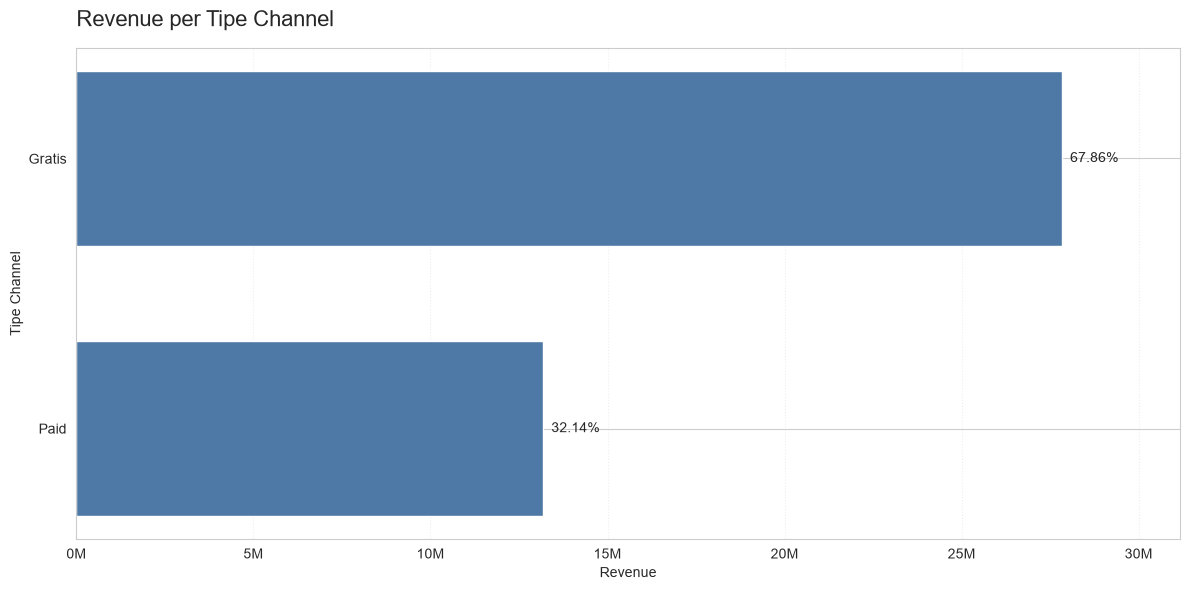

In [59]:
# Pastikan memakai data lengkap, bukan hanya subset paid
required_cols = {'ad_cost', 'revenue'}
missing_cols = required_cols - set(df.columns)

if missing_cols:
    raise KeyError(f'Kolom tidak ditemukan di df: {sorted(missing_cols)}')

# Klasifikasi berdasarkan biaya iklan
channel_data = df.copy()
channel_data['Tipe Channel'] = np.where(
    channel_data['ad_cost'].fillna(0) > 0,
    'Paid',
    'Gratis'
)

# Total revenue dan persentase kontribusinya
revenue_by_channel = (
    channel_data.groupby('Tipe Channel')['revenue']
    .sum()
    .reindex(['Gratis', 'Paid'])
    .dropna()
)

total_revenue = revenue_by_channel.sum()
if total_revenue == 0:
    raise ValueError('Total revenue bernilai 0; persentase tidak dapat dihitung.')

revenue_share = revenue_by_channel / total_revenue * 100

# Grafik horizontal seperti contoh
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    revenue_by_channel.index,
    revenue_by_channel.values,
    color='#4E79A7',
    height=0.65
)

ax.invert_yaxis()
ax.set_title('Revenue per Tipe Channel', loc='left', fontsize=16, pad=16)
ax.set_xlabel('Revenue')
ax.set_ylabel('Tipe Channel')
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:.0f}M')
)
ax.grid(axis='x', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.set_xlim(0, revenue_by_channel.max() * 1.12)

for bar, channel in zip(bars, revenue_by_channel.index):
    ax.annotate(
        f'{revenue_share.loc[channel]:.2f}%',
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords='offset points',
        va='center'
    )

plt.tight_layout()
plt.show()

### Biaya Akuisisi: ROAS, CAC, dan *Break-even Margin*
Indikator yang digunakan:
- **ROAS** (*return on ad spend*) = pendapatan ÷ biaya iklan
- **CAC** (*customer acquisition cost*) = biaya iklan ÷ jumlah pembeli
- ***Break-even margin*** = 1 ÷ ROAS, yaitu margin kotor minimum agar iklan tidak merugi

,Nilai
Pendapatan Paid (Rp),"13,177,258.00"
Biaya iklan (Rp),"10,948,907.00"
ROAS,1.20
CAC per pembeli (Rp),"214,684.45"
Break-even margin,0.83


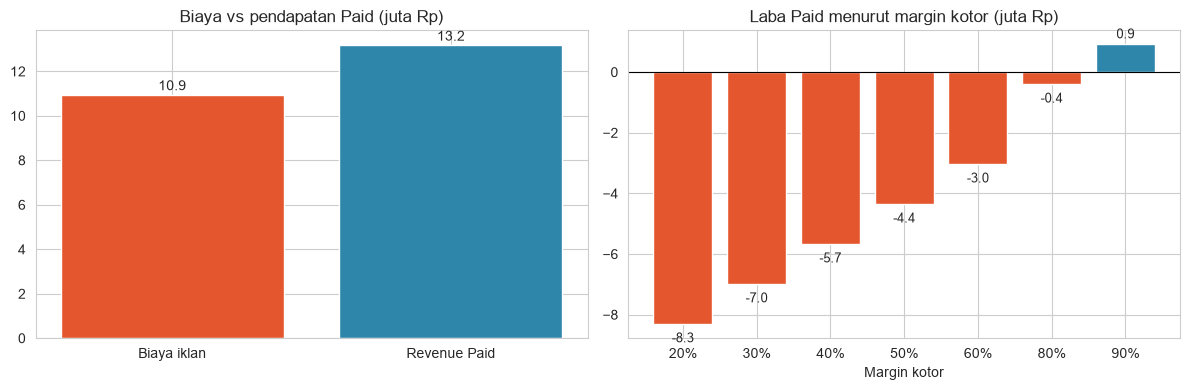

In [ ]:
paid, free = df[df.tipe_channel=='Paid'], df[df.tipe_channel=='Gratis']
rev, cost, buyers = paid.revenue.sum(), paid.ad_cost.sum(), paid.purchase.sum()
roas = rev / cost
display(pd.Series({'Pendapatan Paid (Rp)': rev, 'Biaya iklan (Rp)': cost, 'ROAS': roas,
                   'CAC per pembeli (Rp)': cost/buyers, 'Break-even margin': 1/roas}).to_frame('Nilai'))

margin = np.array([.2, .3, .4, .5, .6, .8, .9]); profit = (rev*margin - cost)/1e6
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(['Biaya iklan', 'Revenue Paid'], [cost/1e6, rev/1e6], color=[C_PAID, '#2E86AB']); ax[0].set_title('Biaya vs pendapatan Paid (juta Rp)')
for i, v in enumerate([cost/1e6, rev/1e6]): ax[0].text(i, v+.2, f'{v:.1f}', ha='center')
ax[1].bar([f'{m:.0%}' for m in margin], profit, color=[C_PAID if p < 0 else C_FREE for p in profit])
ax[1].axhline(0, color='k', lw=.8); ax[1].set(title='Laba Paid menurut margin kotor (juta Rp)', xlabel='Margin kotor')
for i, v in enumerate(profit): ax[1].text(i, v + (.2 if v >= 0 else -.6), f'{v:.1f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Temuan:**
- Paid Ads mengeluarkan biaya sekitar Rp10,95 juta untuk memperoleh pendapatan sekitar Rp13,18 juta, sehingga **ROAS sebesar 1,20**.
- **CAC sekitar Rp214 ribu** per pembeli, sedangkan rata-rata pembelanjaan pembeli hanya sekitar Rp258 ribu. Sebagian besar pendapatan terserap untuk biaya akuisisi.
- ***Break-even margin* sekitar 83%.** Pada margin kotor yang lazim (20–60%), Paid Ads mengalami kerugian sekitar Rp3–8 juta. Sebagai pembanding, channel gratis menghasilkan pendapatan sekitar Rp27,8 juta tanpa biaya iklan.

## Pendapatan Bersih setelah Bayar Biaya Iklan
Perbandingan yang setara dilakukan dengan mengurangkan biaya iklan per pengguna dari pendapatan per pengguna.

,revenue,biaya,net
tipe_channel,,,
Paid,"52,499","43,621","8,878"
Gratis,"50,686",0,"50,686"


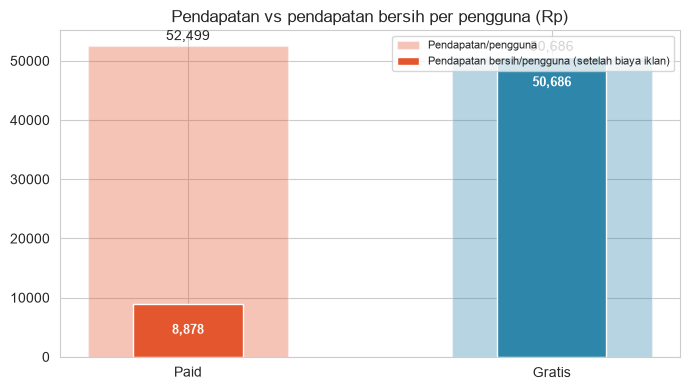

In [ ]:
n = df.groupby('tipe_channel').agg(revenue=('revenue','mean'), biaya=('ad_cost','mean'), net=('revenue_bersih','mean')).loc[['Paid','Gratis']]
display(n.style.format('{:,.0f}'))
fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(2)
ax.bar(x, n.revenue, .55, color=[C_PAID, C_FREE], alpha=.35, label='Pendapatan/pengguna')
ax.bar(x, n.net, .3, color=[C_PAID, C_FREE], label='Pendapatan bersih/pengguna (setelah biaya iklan)')
for i, g in enumerate(n.index):
    ax.text(i, n.revenue[g]+1000, f'{n.revenue[g]:,.0f}', ha='center'); ax.text(i, n.net[g]-5000, f'{n.net[g]:,.0f}', ha='center', fontsize=9, color='white', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(n.index); ax.set_title('Pendapatan vs pendapatan bersih per pengguna (Rp)'); ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

**Temuan:** Pendapatan per pengguna pada Paid Ads (sekitar Rp52,5 ribu) setara dengan channel gratis (sekitar Rp50,7 ribu). Setelah dikurangi biaya iklan (sekitar Rp43,6 ribu per pengguna), Paid Ads hanya menyisakan sekitar Rp8,9 ribu, sedangkan channel gratis tetap sekitar Rp50,7 ribu. **Channel gratis memberikan nilai bersih yang jauh lebih tinggi.**

Pertanyaan lanjutan: apakah seluruh bagian Paid Ads berkinerja rendah, atau terdapat bagian yang layak dipertahankan?

### Membedah Kinerja Paid Ads
Kinerja Paid Ads diuraikan berdasarkan **sumber iklan (*source*)** dan **besaran biaya per pengguna**.

,Pengguna,Konversi,Revenue,Biaya,ROAS,CAC
source,,,,,,
google,42,21.4%,"2,821,780","1,852,968",1.52,"205,885"
facebook,40,22.5%,"2,350,138","1,682,633",1.40,"186,959"
tiktok,40,30.0%,"2,525,408","1,844,773",1.37,"153,731"
email,43,18.6%,"2,135,756","1,703,358",1.25,"212,920"
instagram,41,17.1%,"1,969,911","1,912,808",1.03,"273,258"
direct,45,13.3%,"1,374,265","1,952,367",0.70,"325,394"


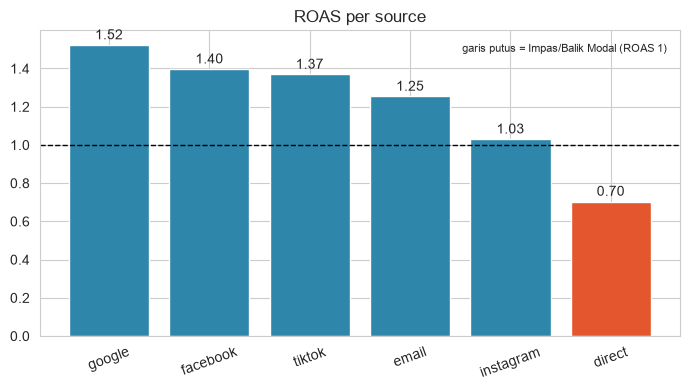

In [ ]:
def ringkas(x):
    return pd.Series({'Pengguna': len(x), 'Konversi': x.purchase.mean(), 'Revenue': x.revenue.sum(), 'Biaya': x.ad_cost.sum(),
                      'ROAS': x.revenue.sum()/x.ad_cost.sum(), 'CAC': x.ad_cost.sum()/max(x.purchase.sum(), 1)})
fmt = {'Pengguna':'{:,.0f}','Konversi':'{:.1%}','Revenue':'{:,.0f}','Biaya':'{:,.0f}','ROAS':'{:.2f}','CAC':'{:,.0f}'}
by_src = paid.groupby('source')[paid.columns].apply(ringkas).sort_values('ROAS', ascending=False)
display(by_src.style.format(fmt))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_src.index.astype(str), by_src.ROAS, color=[C_FREE if r >= 1 else C_PAID for r in by_src.ROAS]); ax.axhline(1, color='k', ls='--', lw=1)
ax.set_title('ROAS per source'); ax.tick_params(axis='x', rotation=20)
for i, v in enumerate(by_src.ROAS): ax.text(i, v+.03, f'{v:.2f}', ha='center')
ax.text(.98, .93, 'garis putus = Impas/Balik Modal (ROAS 1)', transform=ax.transAxes, ha='right', fontsize=8)
plt.tight_layout(); plt.show()

,Pengguna,Konversi,Revenue,Biaya,ROAS,CAC
device,,,,,,
Desktop,87,19.5%,"4,695,313","3,760,999",1.25,"221,235"
Mobile,155,21.3%,"8,141,618","6,734,485",1.21,"204,075"
Tablet,9,11.1%,"340,327","453,423",0.75,"453,423"


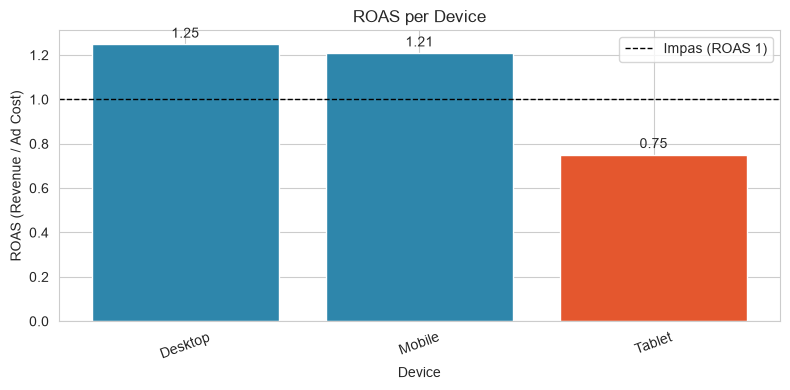

In [ ]:
# Menghitung dan menampilkan ROAS per device
by_device = (
    paid.groupby('device')[paid.columns]
    .apply(ringkas)
    .sort_values('ROAS', ascending=False)
)

display(by_device.style.format(fmt))

# Membuat grafik
fig, ax = plt.subplots(figsize=(8, 4))
colors = [C_FREE if roas >= 1 else C_PAID for roas in by_device['ROAS']]

ax.bar(by_device.index.astype(str), by_device['ROAS'], color=colors)
ax.axhline(
    1,
    color='black',
    linestyle='--',
    linewidth=1,
    label='Impas (ROAS 1)'
)

ax.set_title('ROAS per Device')
ax.set_xlabel('Device')
ax.set_ylabel('ROAS (Revenue / Ad Cost)')
ax.tick_params(axis='x', rotation=20)
ax.legend()

for i, roas in enumerate(by_device['ROAS']):
    ax.text(i, roas + 0.03, f'{roas:.2f}', ha='center')

plt.tight_layout()
plt.show()

**Temuan:**
- **Berdasarkan *source*:** Google (ROAS 1,52), Facebook (1,40), dan TikTok (1,37) menunjukkan kinerja terbaik; TikTok memiliki konversi tertinggi dan CAC terendah. *Source* Direct (ROAS 0,70) mengalami kerugian, sedangkan Instagram mendekati titik impas (1,03).
- **Berdasarkan *device*:** Desktop memiliki ROAS tertinggi (1,25), sedikit di atas Mobile (1,21). Desktop dan Mobile berada di atas garis impas ROAS 1. Tablet memiliki ROAS terendah (0,75), berada di bawah garis impas.

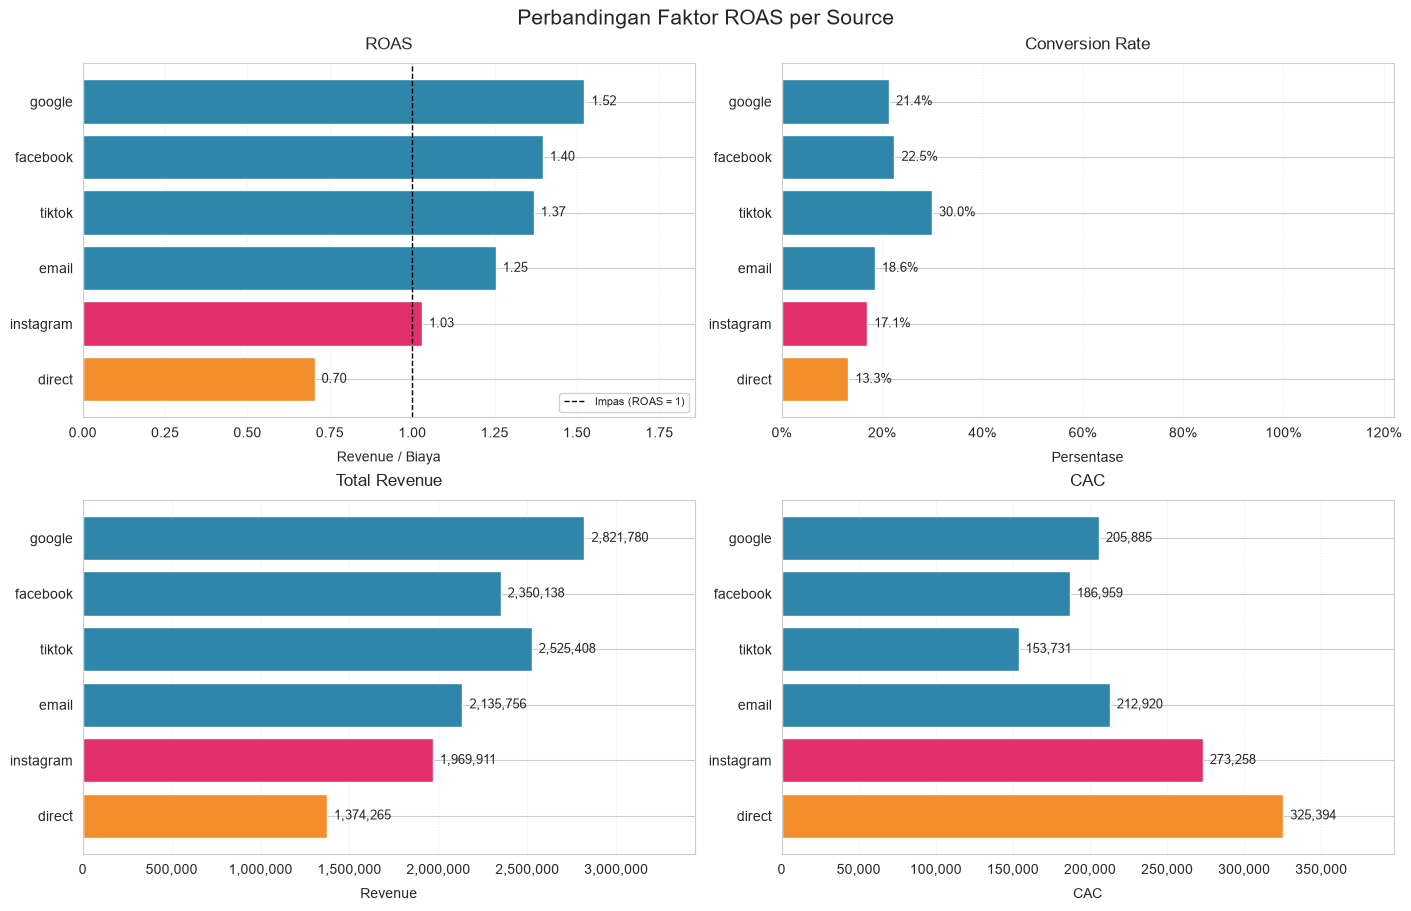

In [ ]:
plot_data = source_check.sort_values('ROAS', ascending=False).copy()

# Biaya akuisisi per pembelian ditampilkan dengan nama CAC
plot_data['CAC'] = plot_data['Biaya'].div(
    plot_data['Pembelian'].replace(0, float('nan'))
)

sources = plot_data.index.astype(str)

# Warna diselaraskan dengan grafik sebelumnya
source_colors = {
    'instagram': '#E1306C',
    'direct': '#F28E2B'
}
colors = [
    source_colors.get(source.lower(), C_FREE)
    for source in sources
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    constrained_layout=True
)

plots = [
    ('ROAS', 'ROAS', 'Revenue / Biaya'),
    ('Conversion_Rate', 'Conversion Rate', 'Persentase'),
    ('Revenue', 'Total Revenue', 'Revenue'),
    ('CAC', 'CAC', 'CAC')
]

for ax, (column, title, xlabel) in zip(axes.flat, plots):
    values = plot_data[column]
    bars = ax.barh(sources, values, color=colors)

    ax.invert_yaxis()
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel(xlabel, labelpad=8)
    ax.grid(axis='x', linestyle=':', alpha=0.4)
    ax.set_axisbelow(True)

    if column == 'Conversion_Rate':
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f'{value:.0%}')
        )
        labels = [f'{value:.1%}' for value in values]
    elif column == 'ROAS':
        labels = [f'{value:.2f}' for value in values]
    else:
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f'{value:,.0f}')
        )
        labels = [f'{value:,.0f}' for value in values]

    ax.set_xlim(0, max(values.max(), 1) * 1.22)

    for bar, label in zip(bars, labels):
        ax.annotate(
            label,
            xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
            xytext=(5, 0),
            textcoords='offset points',
            va='center',
            fontsize=9,
            clip_on=False
        )

    if column == 'ROAS':
        ax.axvline(
            1,
            color='black',
            linestyle='--',
            linewidth=1,
            label='Impas (ROAS = 1)'
        )
        ax.legend(
            loc='lower right',
            frameon=True,
            framealpha=0.9,
            fontsize=8
        )

fig.suptitle('Perbandingan Faktor ROAS per Source', fontsize=15)
plt.show()

#### Temuan dan Insight ROAS per Source

**Insight:** Berdasarkan metrik pada diagram, Direct menjadi prioritas evaluasi karena ROAS-nya di bawah titik impas. Instagram berada sedikit di atas titik impas, sehingga performanya layak dipantau. TikTok dan Google dapat dijadikan pembanding berdasarkan ROAS, conversion rate, dan CAC yang terlihat.

---
### Kesimpulan dan Rekomendasi

**Apakah *paid ads* lebih efektif dibandingkan channel gratis?** Berdasarkan data yang dianalisis, **tidak**.

**Rekomendasi:**
1. **Tidak meningkatkan anggaran Paid Ads** pada skema saat ini, karena ROAS hanya 1,20 dan biaya per pengguna yang lebih besar tidak berkaitan dengan pendapatan yang lebih besar.
2. **Menguji sebelum menambah biaya:** pengguna Paid tidak terbukti lebih berkualitas daripada channel gratis, sehingga setiap penambahan biaya sebaiknya diuji terlebih dahulu (misalnya A/B test per *source*) untuk memastikan ada kenaikan pendapatan yang nyata.
3. **Mempertahankan Google, Facebook, dan TikTok**, serta menghentikan atau mengevaluasi ulang *source* Direct dan Instagram.
4. **Memprioritaskan channel gratis**, terutama Social Media dan Referral.